# GitHub Repository Abandonment — Exploratory Data Analysis

Midterm notebook covering CRISP-DM **Data Understanding → Preprocessing checks → EDA → Feature Engineering**.

- **Input:** `data/pipeline2_output.csv`, produced by the Apache Hop pipelines (`hop/ingest_and_label.hpl` → `hop/feature_engeneering.hpl`).
- **Outputs:** figures in `reports/figures/eda/`, tables in `reports/tables/`.
- **Run:** from the repo root, `jupyter notebook notebooks/eda.ipynb`, then *Run All*. All paths come from `src/config.py`; nothing is hard-coded.

In [1]:
# --- setup -----------------------------------------------------------------
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():          # notebook started from notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

from src import config
from src.preprocess import build_preprocessor, feature_columns, get_train_test

FIG_DIR = config.REPORTS_DIR / "figures" / "eda"
TAB_DIR = config.REPORTS_DIR / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

# Figure style: sized for an IEEE single column (3.5 in) / double column (7.16 in).
ACTIVE, ABANDONED = "#2a78d6", "#eb6834"          # validated categorical pair
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
CLASS_COLORS = {0: ACTIVE, 1: ABANDONED}
CLASS_NAMES = {0: "Active", 1: "Abandoned"}
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.fontsize": 7.5,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
})
SINGLE, DOUBLE = 3.5, 7.16

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    fig.savefig(FIG_DIR / f"{name}.pdf")   # vector copy for the LaTeX/IEEE report
    plt.show()

pd.set_option("display.width", 140, "display.max_columns", 40)
print("Project root:", ROOT)

Project root: /home/claude/repo


## 1. Data understanding

### 1.1 Source and provenance

- **Dataset:** *GitHub Public Repository Metadata* (Kaggle, `pelmers/github-repository-metadata-with-5-stars`): a static snapshot of all public GitHub repositories with at least 5 stars.
- **Snapshot reference date:** the most recent `pushedAt` in the full dataset. Recency and age are measured from this date, not from today.
- **Sample:** 5,000 repositories, drawn by `scritpts/sampleDataset.py`, stratified by label × primary language. Only repositories at least 24 months old are eligible, so every one has had time to become abandoned.
- **Label:** `abandoned = 1` if there was no push for more than 365 days before the snapshot.

In [2]:
df = pd.read_csv(config.DATA_PATH)
rejected = pd.read_csv(config.REJECTED_PATH)

created = pd.to_datetime(df["createdAt"], utc=True)
pushed = pd.to_datetime(df["pushedAt"], utc=True)
snapshot = (pushed + pd.to_timedelta(df["days_since_last_push"], unit="D")).max()  # days are floored, so this is the reference date

print(f"Rows x columns : {df.shape[0]:,} x {df.shape[1]}")
print(f"Snapshot date  : {snapshot.date()}  (pushedAt + days_since_last_push)")
print(f"Created between: {created.min().date()} and {created.max().date()}")
print(f"Label check    : abandoned == (days_since_last_push > 365) for every row -> "
      f"{((df.days_since_last_push > 365).astype(int) == df.abandoned).all()}")
df.head(3).T

Rows x columns : 4,973 x 32
Snapshot date  : 2025-09-13  (pushedAt + days_since_last_push)
Created between: 2009-02-06 and 2023-09-14
Label check    : abandoned == (days_since_last_push > 365) for every row -> True


,0,1,2
abandoned,1,1,1
assignableUserCount,1,1,1
codeOfConduct,NaN,NaN,NaN
createdAt,2021-01-03T07:47:56.000Z,2020-06-12T09:02:16.000Z,2019-01-02T19:49:46.000Z
days_since_last_push,1557,1479,1845
defaultBranchCommitCount,33,12,225
description,NaN,Code for the paper 'Learning TSP Requires Reth...,16 projects in the framework of Computer Visio...
diskUsageKb,3989,55678,113486
forks,0,45,12
isArchived,Y,Y,N


### 1.2 Data dictionary

Each variable has one **role**:
- **target**: what we predict.
- **feature**: an input to a future model.
- **leakage**: excluded because it encodes the target.
- **identifier**: names and IDs.
- **support**: kept for checks and for the planned survival analysis.

In [3]:
DICT = [
    # column, unit, description, role
    ("abandoned", "0/1", "No push in the 365 days before the snapshot", "target"),
    ("assignableUserCount", "users", "Users who can be assigned issues (collaborators)", "feature"),
    ("codeOfConduct", "text", "Code of conduct name, if any", "support"),
    ("createdAt", "timestamp", "Repository creation time (UTC)", "support"),
    ("days_since_last_push", "days", "Snapshot date minus pushedAt", "leakage"),
    ("defaultBranchCommitCount", "commits", "Commits on the default branch (lifetime)", "feature"),
    ("description", "text", "Repository description", "support"),
    ("diskUsageKb", "KB", "Repository size on disk", "feature"),
    ("forks", "forks", "Number of forks", "feature"),
    ("isArchived", "Y/N", "Archived by the owner", "leakage"),
    ("issues", "issues", "Issues (all states)", "feature"),
    ("languageCount", "languages", "Languages detected in the repo", "feature"),
    ("license", "text", "License name ('none' if missing)", "support"),
    ("name", "text", "Repository name", "identifier"),
    ("nameWithOwner", "text", "owner/name, unique key", "identifier"),
    ("owner", "text", "Owner login", "identifier"),
    ("primaryLanguage", "text", "Main language, lower-case ('unknown' if missing)", "support"),
    ("pullRequests", "PRs", "Pull requests (all states)", "feature"),
    ("pushedAt", "timestamp", "Last push time (UTC)", "leakage"),
    ("repo_age_days", "days", "Snapshot date minus createdAt", "feature"),
    ("stars", "stars", "Stargazers at snapshot", "feature"),
    ("topicCount", "topics", "Topics attached to the repo", "feature"),
    ("watchers", "users", "Watchers", "feature"),
    ("commits_per_day", "commits/day", "defaultBranchCommitCount / repo_age_days (Hop)", "feature"),
    ("stars_per_day", "stars/day", "stars / repo_age_days (Hop)", "feature"),
    ("issues_per_pr", "ratio", "issues / pullRequests, or issues if no PRs (Hop)", "feature"),
    ("has_license", "0/1", "License present (Hop)", "feature"),
    ("has_description", "0/1", "Description present (Hop)", "feature"),
    ("description_length", "characters", "Description length (Hop)", "feature"),
    ("has_code_of_conduct", "0/1", "Real code of conduct present (Hop)", "feature"),
    ("language_group", "category", "Top-15 languages + unknown, rest 'other' (Hop)", "feature"),
    ("license_group", "category", "6 common licenses + none, rest 'other' (Hop)", "feature"),
]
dictionary = pd.DataFrame(DICT, columns=["column", "unit", "description", "role"])
dictionary.insert(1, "dtype", dictionary["column"].map(df.dtypes.astype(str)))
assert set(dictionary["column"]) == set(df.columns), set(df.columns) ^ set(dictionary["column"])
dictionary.to_csv(TAB_DIR / "data_dictionary.csv", index=False)
print(dictionary["role"].value_counts().to_string())
dictionary

role
feature       20
support        5
leakage        3
identifier     3
target         1


,column,dtype,unit,description,role
0,abandoned,int64,0/1,No push in the 365 days before the snapshot,target
1,assignableUserCount,int64,users,Users who can be assigned issues (collaborators),feature
2,codeOfConduct,object,text,"Code of conduct name, if any",support
3,createdAt,object,timestamp,Repository creation time (UTC),support
4,days_since_last_push,int64,days,Snapshot date minus pushedAt,leakage
5,defaultBranchCommitCount,int64,commits,Commits on the default branch (lifetime),feature
6,description,object,text,Repository description,support
7,diskUsageKb,int64,KB,Repository size on disk,feature
8,forks,int64,forks,Number of forks,feature
9,isArchived,object,Y/N,Archived by the owner,leakage


## 2. Preprocessing: data-quality checks

The cleaning itself runs in Apache Hop. This section documents what each step changed, as before/after checks.

### 2.1 Row flow through the pipelines

In [4]:
SAMPLE_JSON = config.DATA_DIR / "repos_sample_5000.json"
P1_CSV = config.DATA_DIR / "pipeline1_output.csv"
n_sample = len(pd.read_json(SAMPLE_JSON)) if SAMPLE_JSON.exists() else 5000
n_p1 = len(pd.read_csv(P1_CSV)) if P1_CSV.exists() else len(df) + len(rejected)

flow = pd.DataFrame([
    ("Stratified sample (sampleDataset.py)", n_sample, "", ""),
    ("Pipeline 1: age_check (repo_age_days >= 730)", n_p1, n_sample - n_p1, "age between 720 and 729 days (sampler used 24x30)"),
    ("Pipeline 2: Filter rows (no nulls in key counts)", len(df), n_p1 - len(df), "null commit count -> data/rejected_rows.csv"),
], columns=["step", "rows_out", "rows_removed", "reason"])
flow.to_csv(TAB_DIR / "row_flow.csv", index=False)
print(f"Rejected rows: {len(rejected)}, abandoned: {rejected.abandoned.mean():.0%}, "
      f"null commit count: {rejected.defaultBranchCommitCount.isna().all()}")
flow

Rejected rows: 9, abandoned: 100%, null commit count: True


,step,rows_out,rows_removed,reason
0,Stratified sample (sampleDataset.py),5000,,
1,Pipeline 1: age_check (repo_age_days >= 730),4982,18,age between 720 and 729 days (sampler used 24x30)
2,Pipeline 2: Filter rows (no nulls in key counts),4973,9,null commit count -> data/rejected_rows.csv


### 2.2 Missing values

Hop replaces missing `primaryLanguage` with `unknown` and missing `license` with `none`. Those placeholders are counted as missing here, so the table shows the original gaps.

In [5]:
placeholders = {"primaryLanguage": "unknown", "license": "none"}
miss = {}
for c in df.columns:
    m = df[c].isna()
    if c in placeholders:
        m = m | (df[c] == placeholders[c])
    miss[c] = m.sum()
missing = (pd.DataFrame({"missing": pd.Series(miss)})
           .assign(pct=lambda t: (100 * t.missing / len(df)).round(1))
           .query("missing > 0").sort_values("missing", ascending=False))
treatment = {
    "codeOfConduct": "kept as missing; encoded as has_code_of_conduct = 0",
    "license": "Hop IfNull -> 'none'; has_license = 0; license_group = 'none'",
    "description": "kept as missing; has_description = 0, description_length = 0",
    "primaryLanguage": "Hop IfNull -> 'unknown' (own category)",
}
missing["treatment"] = missing.index.map(treatment)
missing.to_csv(TAB_DIR / "missing_values.csv")
missing

,missing,pct,treatment
codeOfConduct,4752,95.6,kept as missing; encoded as has_code_of_conduc...
license,2339,47.0,Hop IfNull -> 'none'; has_license = 0; license...
description,637,12.8,"kept as missing; has_description = 0, descript..."
primaryLanguage,369,7.4,Hop IfNull -> 'unknown' (own category)


**Missing values are informative here, so no rows are dropped and no values are imputed.** A repo without a license or a description is a fact about the repo, not a measurement error, so each gap becomes a 0/1 flag. The only rows removed are the 9 with a missing *commit count*, which is a real data error. All 9 are empty placeholder repos.

In [6]:
# Abandon rate when the field is missing vs present, to check the gaps carry signal.
rows = []
for c, ph in [("license", "none"), ("description", None), ("codeOfConduct", None), ("primaryLanguage", "unknown")]:
    is_missing = df[c].isna() | ((df[c] == ph) if ph else False)
    rows.append((c, df.loc[is_missing, "abandoned"].mean(), df.loc[~is_missing, "abandoned"].mean()))
pd.DataFrame(rows, columns=["column", "abandon_rate_if_missing", "abandon_rate_if_present"]).round(3)

,column,abandon_rate_if_missing,abandon_rate_if_present
0,license,0.912,0.775
1,description,0.887,0.833
2,codeOfConduct,0.853,0.548
3,primaryLanguage,0.864,0.838


### 2.3 Duplicates, types and categories

In [7]:
checks = {
    "exact duplicate rows": int(df.duplicated().sum()),
    "duplicate nameWithOwner (case-insensitive)": int(df["nameWithOwner"].str.lower().duplicated().sum()),
    "string cells with leading/trailing spaces": int(sum((df[c].dropna() != df[c].dropna().str.strip()).sum()
                                                        for c in df.select_dtypes("object"))),
    "primaryLanguage values not lower-case": int((df["primaryLanguage"] != df["primaryLanguage"].str.lower()).sum()),
    "negative values in count columns": int((df.select_dtypes("number") < 0).sum().sum()),
    "pushedAt before createdAt (imported repos)": int(((created - pushed).dt.total_seconds() > 1).sum()),
    "repo_age_days below 730": int((df["repo_age_days"] < 730).sum()),
    "isArchived values outside Y/N": int((~df["isArchived"].isin(["Y", "N"])).sum()),
}
pd.Series(checks, name="count").to_frame()

,count
exact duplicate rows,0
duplicate nameWithOwner (case-insensitive),0
string cells with leading/trailing spaces,0
primaryLanguage values not lower-case,0
negative values in count columns,0
pushedAt before createdAt (imported repos),18
repo_age_days below 730,0
isArchived values outside Y/N,0


In [8]:
# Columns removed in Hop because they carry no information in this sample.
print("Hop 'drop constant columns' removed isFork, forkingAllowed, parent (one value / all empty).")
print("Remaining columns with a single value:", [c for c in df.columns if df[c].nunique(dropna=False) == 1] or "none")

Hop 'drop constant columns' removed isFork, forkingAllowed, parent (one value / all empty).


Remaining columns with a single value: none


### 2.4 Outliers

The count variables are extremely right-skewed. The 1.5×IQR rule flags 10–16 % of every column as an outlier. But those values are **real, popular repositories**, not errors. A repo with 17,788 stars exists. Removing them would delete exactly the repositories most likely to stay active.

**Treatment:** keep every row, and apply a `log1p` transform to the count features in the modeling pipeline. It's fitted on the training split only (`src/preprocess.py`). Section 2.5 checks whether the extremes really are genuine.

In [9]:
NUM = config.NUMERIC_FEATURES + ["description_length"]
out_rows = []
for c in NUM:
    x = df[c]
    q1, q3 = x.quantile([0.25, 0.75]); iqr = q3 - q1
    out_rows.append({
        "feature": c, "min": x.min(), "median": x.median(), "max": x.max(),
        "skew_raw": x.skew(), "skew_log1p": np.log1p(x).skew(),
        "iqr_outliers_pct": 100 * ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).mean(),
        "zeros_pct": 100 * (x == 0).mean(),
    })
outliers = pd.DataFrame(out_rows).set_index("feature").round(2)
outliers.to_csv(TAB_DIR / "outliers_skew.csv")
outliers

,min,median,max,skew_raw,skew_log1p,iqr_outliers_pct,zeros_pct
feature,,,,,,,
assignableUserCount,0.0,1.00,2028.00,23.92,4.05,11.78,1.49
defaultBranchCommitCount,1.0,27.00,701620.00,42.40,0.77,13.45,0.00
diskUsageKb,0.0,612.00,18168678.00,38.41,0.22,16.21,0.34
forks,0.0,4.00,3078.00,16.35,0.94,12.43,15.50
issues,0.0,1.00,11775.00,49.19,1.52,14.78,45.83
languageCount,0.0,2.00,47.00,4.73,0.42,4.73,7.48
pullRequests,0.0,1.00,16851.00,44.33,1.52,15.99,49.13
repo_age_days,730.0,2394.00,6063.00,0.54,-0.32,0.00,0.00
stars,5.0,12.00,17788.00,19.46,1.63,13.51,0.00


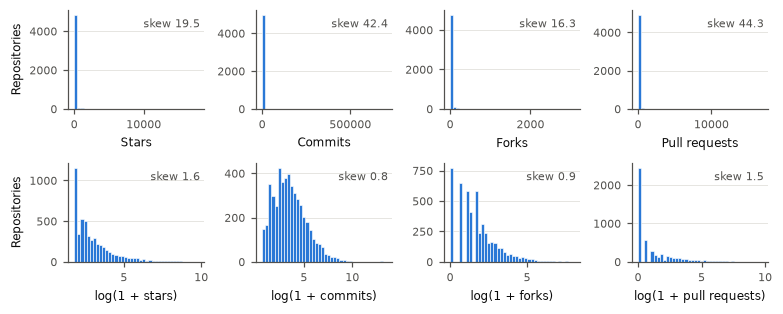

In [10]:
# Fig: raw vs log1p distributions for four representative counts
show = [("stars", "Stars"), ("defaultBranchCommitCount", "Commits"), ("forks", "Forks"), ("pullRequests", "Pull requests")]
fig, axes = plt.subplots(2, 4, figsize=(DOUBLE, 2.9))
for j, (c, label) in enumerate(show):
    x = df[c]
    for i, (vals, xl) in enumerate([(x, label), (np.log1p(x), f"log(1 + {label.lower()})")]):
        ax = axes[i, j]
        ax.hist(vals, bins=40, color=ACTIVE, edgecolor="white", linewidth=0.4)
        ax.set_xlabel(xl)
        ax.text(0.97, 0.92, f"skew {vals.skew():.1f}", transform=ax.transAxes, ha="right", va="top", color=INK2, fontsize=7)
        if j == 0:
            ax.set_ylabel("Repositories")
        ax.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "fig_skew_log1p")

### 2.5 Validating the extreme values

The IQR rule only says a value is *far from the others*, not whether it is *correct*. To decide, we look at the most extreme repositories themselves and check that their values agree with each other.

In [11]:
show_cols = ["nameWithOwner", "stars", "forks", "watchers", "defaultBranchCommitCount",
             "pullRequests", "issues", "assignableUserCount"]
for c in ["stars", "pullRequests", "defaultBranchCommitCount", "assignableUserCount"]:
    print(f"\nTop 3 by {c}")
    print(df.nlargest(3, c)[show_cols].to_string(index=False))


Top 3 by stars
             nameWithOwner  stars  forks  watchers  defaultBranchCommitCount  pullRequests  issues  assignableUserCount
    so-fancy/diff-so-fancy  17788    335       115                       733           212     292                    6
mozilla-mobile/firefox-ios  12685   3078       522                     18926         16851   11775                   84
  Hackl0us/SS-Rule-Snippet  11174   1836       284                       401            71     154                    1

Top 3 by pullRequests
                           nameWithOwner  stars  forks  watchers  defaultBranchCommitCount  pullRequests  issues  assignableUserCount
              mozilla-mobile/firefox-ios  12685   3078       522                     18926         16851   11775                   84
kubevirt/hyperconverged-cluster-operator    165    158        10                      2229          3581     152                   61
                   kata-containers/tests    142    194        53               

In [12]:
# Consistency checks: real data agrees with itself, errors tend to stand alone
consistency = {
    "negative counts": int((df[config.NUMERIC_FEATURES] < 0).sum().sum()),
    "> 50 pull requests but < 5 commits": int(((df.pullRequests > 50) & (df.defaultBranchCommitCount < 5)).sum()),
    "Spearman rho, stars vs forks": round(df[["stars", "forks"]].corr(method="spearman").iat[0, 1], 2),
    "Spearman rho, stars vs watchers": round(df[["stars", "watchers"]].corr(method="spearman").iat[0, 1], 2),
    "repos with > 50 commits/day": int((df.commits_per_day > 50).sum()),
    "repos with > 100 assignable users": int((df.assignableUserCount > 100).sum()),
}
big_orgs = df.loc[df.assignableUserCount > 100, "owner"].value_counts().head(3).to_dict()
print("Owners of repos with > 100 assignable users:", big_orgs)
pd.Series(consistency, name="value").to_frame()

Owners of repos with > 100 assignable users: {'microsoft': 7, 'GoogleCloudPlatform': 3, 'OCA': 1}


,value
negative counts,0.00
> 50 pull requests but < 5 commits,0.00
"Spearman rho, stars vs forks",0.68
"Spearman rho, stars vs watchers",0.52
repos with > 50 commits/day,4.00
repos with > 100 assignable users,20.00


**Verdict.**
- **Stars, forks, pull requests and issues: genuine.** The top repositories are well-known projects (`mozilla-mobile/firefox-ios`, `so-fancy/diff-so-fancy`). Their values are consistent with each other, and no value is impossible. They're kept as they are, log-transformed.
- **Commit count: real but misleading for a few repos.** The top three (400k–700k commits, under 15 stars) are copies of Android/Linux kernels that **inherit the upstream history**. Nobody makes 130–300 commits a day. The count is correct, but it measures the kernel's history, not the owner's activity.
- **Assignable users: organisation size, not team size.** Values around 2,000 come from Microsoft and Google Cloud repositories, where every member of the organisation is counted.

**Treatment: winsorising.** These three variables (`defaultBranchCommitCount`, `commits_per_day`, `assignableUserCount`) are capped at their **99th percentile**. No rows are removed, because the labels of these repos are still correct. The cap is **learned on the training split only**, as the first step of the numeric pipeline in `src/preprocess.py`, so no information from the test set is used.

In [13]:
X_tr, X_te, _, _ = get_train_test()
fitted = build_preprocessor(scale=False).fit(X_tr).named_transformers_
caps_learned = {**fitted["num"].named_steps["cap"].caps_, **fitted["ratio"].named_steps["cap"].caps_}
cap_rows = []
for c, cap in caps_learned.items():
    cap_rows.append({
        "feature": c, "cap (train 99th pct)": round(cap, 2), "max before": X_tr[c].max(),
        "train rows capped": int((X_tr[c] > cap).sum()), "test rows capped": int((X_te[c] > cap).sum()),
        "skew of log1p before": round(np.log1p(X_tr[c]).skew(), 2),
        "skew of log1p after": round(np.log1p(X_tr[c].clip(upper=cap)).skew(), 2),
    })
caps = pd.DataFrame(cap_rows).set_index("feature")
caps.to_csv(TAB_DIR / "winsorizing_caps.csv")
caps

,cap (train 99th pct),max before,train rows capped,test rows capped,skew of log1p before,skew of log1p after
feature,,,,,,
defaultBranchCommitCount,3608.45,701620.000000,40,14,0.75,0.56
assignableUserCount,30.00,2028.000000,39,18,4.09,2.48
commits_per_day,1.61,303.600173,40,14,11.87,4.45


## 3. Exploratory data analysis

### 3.1 Target and overall descriptive statistics

In [14]:
counts = df["abandoned"].value_counts().rename(CLASS_NAMES)
print(counts.to_string(), f"\nAbandon rate: {df.abandoned.mean():.1%}")
desc = df[NUM].describe(percentiles=[0.25, 0.5, 0.75, 0.95]).T.round(2)
desc.to_csv(TAB_DIR / "descriptive_stats.csv")
desc

abandoned
Abandoned    4175
Active        798 
Abandon rate: 84.0%


,count,mean,std,min,25%,50%,75%,95%,max
assignableUserCount,4973.0,6.14,80.55,0.0,1.0,1.00,2.00,8.00,2028.00
defaultBranchCommitCount,4973.0,574.35,13462.31,1.0,9.0,27.00,93.00,739.40,701620.00
diskUsageKb,4973.0,29684.24,332338.74,0.0,97.0,612.00,5820.00,77829.40,18168678.00
forks,4973.0,19.81,97.26,0.0,1.0,4.00,10.00,68.40,3078.00
issues,4973.0,18.18,190.63,0.0,0.0,1.00,5.00,53.00,11775.00
languageCount,4973.0,2.45,2.55,0.0,1.0,2.00,3.00,6.00,47.00
pullRequests,4973.0,30.78,282.46,0.0,0.0,1.00,6.00,95.00,16851.00
repo_age_days,4973.0,2569.07,1208.39,730.0,1603.0,2394.00,3387.00,4839.40,6063.00
stars,4973.0,84.61,484.97,5.0,7.0,12.00,32.00,267.80,17788.00
topicCount,4973.0,1.78,3.32,0.0,0.0,0.00,3.00,9.00,20.00


In [15]:
# Medians by class: the 'typical' repo in each group
med = df.groupby("abandoned")[NUM].median().T.rename(columns=CLASS_NAMES)
med["ratio_active_to_abandoned"] = (med["Active"] / med["Abandoned"].replace(0, np.nan)).round(2)
med

abandoned,Active,Abandoned,ratio_active_to_abandoned
assignableUserCount,1.000000,1.000000,1.00
defaultBranchCommitCount,171.500000,20.000000,8.57
diskUsageKb,2673.500000,450.000000,5.94
forks,7.500000,3.000000,2.50
issues,7.000000,0.000000,NaN
languageCount,2.000000,2.000000,1.00
pullRequests,13.000000,0.000000,NaN
repo_age_days,1852.500000,2515.000000,0.74
stars,25.000000,11.000000,2.27
topicCount,0.000000,0.000000,NaN


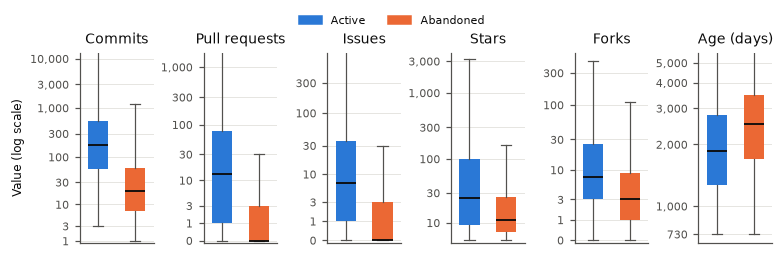

In [16]:
# Fig: distributions by class (log scale) for the activity and popularity counts
panels = [("defaultBranchCommitCount", "Commits"), ("pullRequests", "Pull requests"), ("issues", "Issues"),
          ("stars", "Stars"), ("forks", "Forks"), ("repo_age_days", "Age (days)")]
fig, axes = plt.subplots(1, 6, figsize=(DOUBLE, 2.2))
for ax, (c, label) in zip(axes, panels):
    data = [np.log1p(df.loc[df.abandoned == k, c]) for k in (0, 1)]
    bp = ax.boxplot(data, widths=0.55, patch_artist=True, showfliers=False,
                    medianprops=dict(color=INK, linewidth=1.2), whiskerprops=dict(color=INK2, linewidth=0.8),
                    capprops=dict(color=INK2, linewidth=0.8), boxprops=dict(linewidth=0))
    for patch, k in zip(bp["boxes"], (0, 1)):
        patch.set_facecolor(CLASS_COLORS[k])
    ax.set_xticks([])
    ax.set_title(label)
    ax.grid(axis="x", visible=False)
    lo, hi = min(d.min() for d in data), max(np.percentile(d, 99) for d in data)
    nice = [v for v in [0, 1, 3, 10, 30, 100, 300, 1000, 3000, 10000, 30000] if lo - 0.1 <= np.log1p(v) <= hi]
    if c == "repo_age_days":
        nice = [730, 1000, 2000, 3000, 4000, 5000, 6000]
    ax.set_yticks(np.log1p(nice), [f"{v:,}" for v in nice])
    ax.set_ylim(lo - 0.1, hi)
axes[0].set_ylabel("Value (log scale)")
handles = [plt.Rectangle((0, 0), 1, 1, color=CLASS_COLORS[k]) for k in (0, 1)]
fig.legend(handles, ["Active", "Abandoned"], loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.06))
fig.tight_layout(w_pad=0.6)
save(fig, "fig_box_by_class")

**Reading Fig. "box by class".** Active repositories have about **8.6× more commits** (median 172 vs 20). They also have far more pull requests and issues: the median abandoned repo has **zero** of both. Popularity differs much less, with stars at a median of 25 vs 11 and forks at 7.5 vs 3. **Age goes the other way.** Abandoned repos are older (median 2,515 vs 1,853 days), because an older repo has simply had more time to stop.

### 3.2 Abandonment by category

Abandon rate per group, with a 95 % Wilson confidence interval. The dashed line is the overall rate.

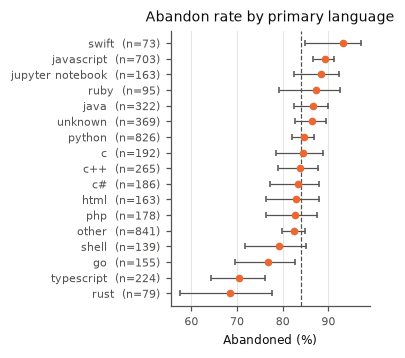

,k,n,rate,lo,hi
language_group,,,,,
rust,54,79,0.684,0.575,0.776
typescript,158,224,0.705,0.643,0.761
go,119,155,0.768,0.695,0.827
shell,110,139,0.791,0.716,0.851
other,694,841,0.825,0.798,0.849
php,147,178,0.826,0.763,0.875
html,135,163,0.828,0.763,0.878
c#,155,186,0.833,0.773,0.880
c++,222,265,0.838,0.789,0.877


In [17]:
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

g = df.groupby("language_group")["abandoned"].agg(k="sum", n="size")
g["rate"] = g.k / g.n
g[["lo", "hi"]] = [wilson(k, n) for k, n in zip(g.k, g.n)]
g = g.sort_values("rate")
g.round(3).to_csv(TAB_DIR / "rate_by_language_group.csv")

fig, ax = plt.subplots(figsize=(SINGLE, 3.3))
y = np.arange(len(g))
ax.errorbar(g.rate * 100, y, xerr=[(g.rate - g.lo) * 100, (g.hi - g.rate) * 100], fmt="o", ms=4,
            color=ABANDONED, ecolor=INK2, elinewidth=0.8, capsize=2)
ax.axvline(df.abandoned.mean() * 100, color=INK2, linestyle="--", linewidth=0.8)
ax.set_yticks(y, [f"{i}  (n={n})" for i, n in zip(g.index, g.n)])
ax.set_xlabel("Abandoned (%)")
ax.set_title("Abandon rate by primary language")
ax.grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "fig_rate_language")
g.round(3)

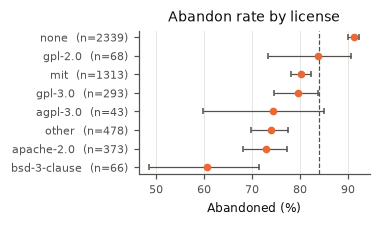

,k,n,rate,lo,hi
license_group,,,,,
bsd-3-clause,40,66,0.606,0.485,0.715
apache-2.0,272,373,0.729,0.682,0.772
other,353,478,0.738,0.697,0.776
agpl-3.0,32,43,0.744,0.598,0.851
gpl-3.0,233,293,0.795,0.745,0.837
mit,1054,1313,0.803,0.780,0.823
gpl-2.0,57,68,0.838,0.733,0.907
none,2134,2339,0.912,0.900,0.923


In [18]:
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

g = df.groupby("license_group")["abandoned"].agg(k="sum", n="size")
g["rate"] = g.k / g.n
g[["lo", "hi"]] = [wilson(k, n) for k, n in zip(g.k, g.n)]
g = g.sort_values("rate")
g.round(3).to_csv(TAB_DIR / "rate_by_license_group.csv")

fig, ax = plt.subplots(figsize=(SINGLE, 2.1))
y = np.arange(len(g))
ax.errorbar(g.rate * 100, y, xerr=[(g.rate - g.lo) * 100, (g.hi - g.rate) * 100], fmt="o", ms=4,
            color=ABANDONED, ecolor=INK2, elinewidth=0.8, capsize=2)
ax.axvline(df.abandoned.mean() * 100, color=INK2, linestyle="--", linewidth=0.8)
ax.set_yticks(y, [f"{i}  (n={n})" for i, n in zip(g.index, g.n)])
ax.set_xlabel("Abandoned (%)")
ax.set_title("Abandon rate by license")
ax.grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "fig_rate_license")
g.round(3)

**Reading the category figures.**
- **Language:** the spread is real but moderate. Rust (68 %) and TypeScript (71 %) are below the 84 % average, and their confidence intervals stay below it. JavaScript (89 %) and Swift (93 %) are above it. Rust and TypeScript are also the youngest languages here, so part of this gap may be **age**, not language.
- **License:** this is the stronger signal. **91 % of repos without a license are abandoned**, against 61–84 % for the common licenses. Choosing a license is a small, early sign that the author intends the project to be used.

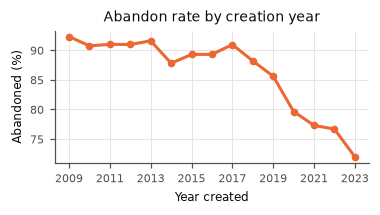

year,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
rate,0.923,0.907,0.91,0.91,0.916,0.878,0.893,0.893,0.91,0.882,0.856,0.796,0.773,0.767,0.72
n,26.000,54.000,111.00,133.00,202.000,246.000,308.000,402.000,431.00,500.000,514.000,619.000,564.000,463.000,400.00


In [19]:
# Abandon rate by creation year: older repos had more time to stop
yr = df.assign(year=created.dt.year).groupby("year")["abandoned"].agg(rate="mean", n="size")
fig, ax = plt.subplots(figsize=(SINGLE, 2.0))
ax.plot(yr.index, yr.rate * 100, color=ABANDONED, linewidth=2, marker="o", ms=4)
ax.set_xlabel("Year created"); ax.set_ylabel("Abandoned (%)")
ax.set_title("Abandon rate by creation year")
ax.set_xticks(yr.index[::2])
fig.tight_layout()
save(fig, "fig_rate_year")
yr.round(3).T

**Reading Fig. "rate by year".** The abandon rate falls from about **90 % for repos created in 2009–2017** to **72 % for those created in 2023**. Age is therefore a **confounder**: older repos look "more abandoned" partly because they've existed longer. Any comparison between groups (languages, licenses) should keep age in mind. This is also the main argument for the survival analysis planned in the next phase, which models *time* until abandonment explicitly.

### 3.3 Correlations

The data is far from normal (see 2.4), so we use **Spearman** rank correlation. It's robust to the skew and to monotonic but non-linear relationships. The target is included as a 0/1 column, so its row is a point-biserial-style rank correlation.

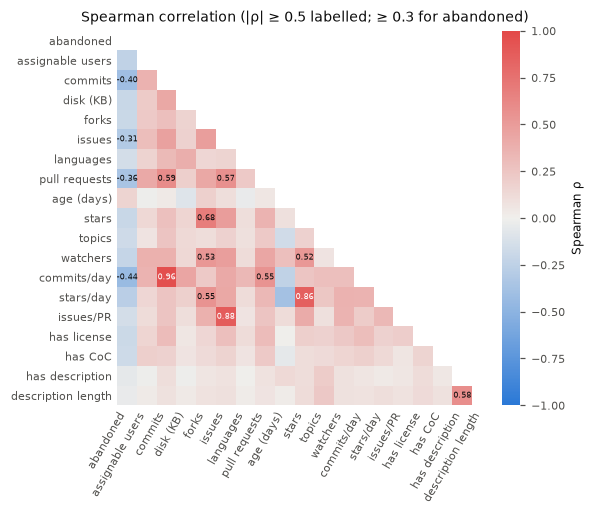

,rho_with_abandoned
commits_per_day,-0.437
defaultBranchCommitCount,-0.404
pullRequests,-0.357
issues,-0.312
stars_per_day,-0.271
assignableUserCount,-0.241
watchers,-0.212
diskUsageKb,-0.202
stars,-0.201
forks,-0.194


In [20]:
corr_cols = ["abandoned"] + config.NUMERIC_FEATURES + config.DERIVED_FEATURES
labels = {"defaultBranchCommitCount": "commits", "assignableUserCount": "assignable users",
          "repo_age_days": "age (days)", "pullRequests": "pull requests", "languageCount": "languages",
          "topicCount": "topics", "diskUsageKb": "disk (KB)", "commits_per_day": "commits/day",
          "stars_per_day": "stars/day", "issues_per_pr": "issues/PR", "has_license": "has license",
          "has_code_of_conduct": "has CoC", "has_description": "has description",
          "description_length": "description length"}
rho = df[corr_cols].corr(method="spearman")
rho.round(3).to_csv(TAB_DIR / "spearman_correlation.csv")
names = [labels.get(c, c) for c in corr_cols]

fig, ax = plt.subplots(figsize=(DOUBLE * 0.8, DOUBLE * 0.66))
masked = rho.where(np.tril(np.ones(rho.shape, dtype=bool), k=-1))   # lower triangle only (matrix is symmetric)
im = ax.imshow(masked, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(names)), names, rotation=60, ha="right")
ax.set_yticks(range(len(names)), names)
ax.grid(False)
ax.tick_params(length=0)
for i in range(len(names)):
    for j in range(len(names)):
        v = rho.iat[i, j]
        if i > j and (abs(v) >= 0.5 or (i > 0 and j == 0 and abs(v) >= 0.3)):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=5.5,
                    color="white" if abs(v) > 0.7 else INK)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cb.set_label("Spearman ρ"); cb.outline.set_visible(False)
ax.set_title("Spearman correlation (|ρ| ≥ 0.5 labelled; ≥ 0.3 for abandoned)")
fig.tight_layout()
save(fig, "fig_spearman")
rho["abandoned"].drop("abandoned").sort_values().round(3).to_frame("rho_with_abandoned")

**Reading the correlation heatmap.**
- **With the target:** the strongest associations with abandonment are all **activity** measures: commits/day (ρ = −0.44), commits (−0.40), pull requests (−0.36) and issues (−0.31). Popularity measures are weaker (stars −0.20, forks −0.19). Age is the only positive one (+0.16).
- **Between features:** three pairs are near-duplicates: commits/day ~ commits (0.96), issues/PR ~ issues (0.88) and stars/day ~ stars (0.86). Each ratio was built from that count, so the pair carries almost the same information. Section 5 deals with this.

## 4. Hypothesis tests

**Choice of test.** The counts are heavily skewed and zero-inflated, so normality is rejected for every one (checked below). The groups are also very unequal (84 / 16). That rules out the t-test and leads to:

- **H1, the primary test:** a two-sided **Mann–Whitney U** test. *H₀:* commit counts have the same distribution in active and abandoned repositories. The effect size is the **rank-biserial correlation** *r*, the probability of superiority rescaled to [−1, 1].
- **H2:** a **χ² test of independence**. *H₀:* having a license is independent of abandonment. The effect size is **Cramér's V**.
- **Secondary screen:** the same tests on every feature, with a **Holm** correction because many tests run at once.

All tests use α = 0.05.

In [21]:
# Normality check that motivates non-parametric tests (D'Agostino K^2 on each class)
norm = {c: max(stats.normaltest(df.loc[df.abandoned == k, c]).pvalue for k in (0, 1))
        for c in config.NUMERIC_FEATURES}
print("Largest normality p-value across features and classes:", f"{max(norm.values()):.1e}",
      "-> normality rejected everywhere" if max(norm.values()) < 0.05 else "")

Largest normality p-value across features and classes: 8.9e-22 -> normality rejected everywhere


In [22]:
def mann_whitney(col):
    a, b = df.loc[df.abandoned == 0, col], df.loc[df.abandoned == 1, col]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    r = 2 * u / (len(a) * len(b)) - 1          # > 0: active repos tend to have higher values
    return {"feature": col, "test": "Mann-Whitney U", "statistic": u, "p": p, "effect": r,
            "effect_name": "rank-biserial r", "median_active": a.median(), "median_abandoned": b.median()}

def chi_square(col):
    t = pd.crosstab(df[col], df.abandoned)
    chi2, p, dof, expected = stats.chi2_contingency(t)
    v = np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))
    return {"feature": col, "test": f"chi-square (dof={dof})", "statistic": chi2, "p": p, "effect": v,
            "effect_name": "Cramér's V", "min_expected": expected.min()}

h1 = mann_whitney("defaultBranchCommitCount")
print("H1  Mann-Whitney U, commits active vs abandoned")
print(f"    median active = {h1['median_active']:.0f}, median abandoned = {h1['median_abandoned']:.0f}")
print(f"    U = {h1['statistic']:,.0f}, p = {h1['p']:.1e}, rank-biserial r = {h1['effect']:.3f}")
print(f"    -> P(random active repo has more commits than random abandoned repo) = {(h1['effect'] + 1) / 2:.2f}")

h2 = chi_square("has_license")
t = pd.crosstab(df.has_license.map({0: "no license", 1: "license"}), df.abandoned.map(CLASS_NAMES))
print("\nH2  chi-square, has_license x abandoned")
print(t.to_string())
print(f"    chi2 = {h2['statistic']:.1f}, p = {h2['p']:.1e}, Cramér's V = {h2['effect']:.3f}, "
      f"smallest expected count = {h2['min_expected']:.0f} (>= 5, test valid)")

H1  Mann-Whitney U, commits active vs abandoned
    median active = 172, median abandoned = 20
    U = 2,723,648, p = 2.7e-178, rank-biserial r = 0.635
    -> P(random active repo has more commits than random abandoned repo) = 0.82

H2  chi-square, has_license x abandoned
abandoned    Abandoned  Active
has_license                   
license           2041     593
no license        2134     205
    chi2 = 172.8, p = 1.8e-39, Cramér's V = 0.186, smallest expected count = 375 (>= 5, test valid)


In [23]:
# Screen of all features, Holm-corrected
tests = [mann_whitney(c) for c in config.NUMERIC_FEATURES + ["description_length"]]
tests += [chi_square(c) for c in ["has_license", "has_description", "has_code_of_conduct", "language_group", "license_group"]]
res = pd.DataFrame(tests)
order = res["p"].sort_values().index
m = len(res); holm = np.empty(m); running = 0.0
for rank, idx in enumerate(order):
    running = max(running, min(1.0, (m - rank) * res.at[idx, "p"]))
    holm[idx] = running
res["p_holm"] = holm
res["significant"] = res["p_holm"] < 0.05
res = res.reindex(res["effect"].abs().sort_values(ascending=False).index)
res[["feature", "test", "p", "p_holm", "effect", "effect_name", "significant"]].to_csv(TAB_DIR / "hypothesis_tests.csv", index=False)
res[["feature", "test", "statistic", "p_holm", "effect", "effect_name", "significant"]].round(4)

,feature,test,statistic,p_holm,effect,effect_name,significant
11,commits_per_day,Mann-Whitney U,2.810710e+06,0.0000,0.6873,rank-biserial r,True
1,defaultBranchCommitCount,Mann-Whitney U,2.723648e+06,0.0000,0.6350,rank-biserial r,True
6,pullRequests,Mann-Whitney U,2.542346e+06,0.0000,0.5262,rank-biserial r,True
4,issues,Mann-Whitney U,2.440487e+06,0.0000,0.4650,rank-biserial r,True
12,stars_per_day,Mann-Whitney U,2.375841e+06,0.0000,0.4262,rank-biserial r,True
10,watchers,Mann-Whitney U,2.210988e+06,0.0000,0.3273,rank-biserial r,True
2,diskUsageKb,Mann-Whitney U,2.193977e+06,0.0000,0.3171,rank-biserial r,True
8,stars,Mann-Whitney U,2.190697e+06,0.0000,0.3151,rank-biserial r,True
3,forks,Mann-Whitney U,2.172294e+06,0.0000,0.3040,rank-biserial r,True
0,assignableUserCount,Mann-Whitney U,2.156906e+06,0.0000,0.2948,rank-biserial r,True


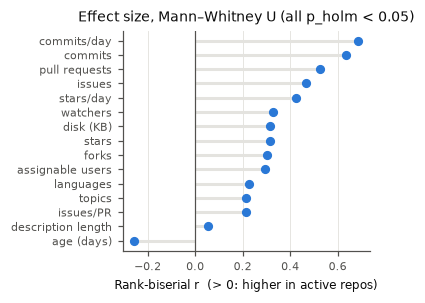

In [24]:
# Fig: effect sizes of the screen (one measure across items -> sorted dot plot)
mw = res[res.test == "Mann-Whitney U"].sort_values("effect")
fig, ax = plt.subplots(figsize=(SINGLE, 2.8))
yy = np.arange(len(mw))
ax.hlines(yy, 0, mw.effect, color=GRID, linewidth=2)
ax.plot(mw.effect, yy, "o", color=ACTIVE, ms=5)
ax.axvline(0, color=INK2, linewidth=0.8)
ax.set_yticks(yy, [labels.get(c, c) for c in mw.feature])
ax.set_xlabel("Rank-biserial r  (> 0: higher in active repos)")
ax.set_title("Effect size, Mann–Whitney U (all p_holm < 0.05)" if mw.significant.all() else "Effect size, Mann–Whitney U")
ax.grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "fig_effect_sizes")

**Interpretation of the tests.**
- **H1 is rejected** (U = 2,723,648, p ≈ 3 × 10⁻¹⁷⁸). The effect is large: r = 0.64, which means a randomly chosen active repo has more commits than a randomly chosen abandoned one **82 % of the time**.
- **H2 is rejected** (χ² = 172.8, p ≈ 2 × 10⁻³⁹), but the association is **weak** (Cramér's V = 0.19). A license matters, but alone it explains little.
- **With n ≈ 5,000, almost everything is "significant".** All 20 screened features pass after Holm correction, so the **effect size, not the p-value, is what ranks the features.** Activity measures dominate (r = 0.46–0.69). Popularity and size are moderate (≈ 0.3). Description length is negligible (0.06).
- **Caveat:** these are snapshot counts, measured *after* the outcome was decided. They describe how abandoned repos differ, not what predicted the abandonment (see the conclusions below).

## 5. Feature engineering

### 5.1 Final feature set

20 input columns, defined in `src/config.py`, in three groups. They're built in Hop Pipeline 2, and the learned transforms are applied in `src/preprocess.py`.

In [25]:
FE = [
    ("Counts (11)", ", ".join(config.NUMERIC_FEATURES[:11]), "raw from dataset", "99th-pct cap (3 vars), median impute, log1p, standardise", "activity, popularity, size, age"),
    ("Ratios (3)", ", ".join(config.NUMERIC_FEATURES[11:]), "created in Hop", "plain log (commits/day, stars/day; cap on commits/day), log1p (issues/PR), standardise", "normalise counts by age / PRs"),
    ("Flags (4)", ", ".join(config.DERIVED_FEATURES), "created in Hop", "standardise", "turn informative missingness into signal"),
    ("Categories (2)", ", ".join(config.CATEGORICAL_FEATURES), "grouped in Hop (fixed lists)", "one-hot encode", "rare levels pooled into 'other'"),
]
pd.DataFrame(FE, columns=["group", "features", "origin", "transform", "why"])

,group,features,origin,transform,why
0,Counts (11),"assignableUserCount, defaultBranchCommitCount,...",raw from dataset,"99th-pct cap (3 vars), median impute, log1p, s...","activity, popularity, size, age"
1,Ratios (3),"commits_per_day, stars_per_day, issues_per_pr",created in Hop,"plain log (commits/day, stars/day; cap on comm...",normalise counts by age / PRs
2,Flags (4),"has_license, has_code_of_conduct, has_descript...",created in Hop,standardise,turn informative missingness into signal
3,Categories (2),"language_group, license_group",grouped in Hop (fixed lists),one-hot encode,rare levels pooled into 'other'


### 5.2 Excluded variables (leakage)

`days_since_last_push` and `pushedAt` define the label. `isArchived` is an owner's declaration of the outcome. Using any of them would let a model read the answer instead of predicting it.

In [26]:
arch = pd.crosstab(df.isArchived, df.abandoned.map(CLASS_NAMES), margins=True)
print(arch.to_string())
print(f"\nArchived repos that are abandoned: {df.loc[df.isArchived == 'Y', 'abandoned'].mean():.1%}")
print("days_since_last_push separates the classes perfectly at 365 days (it IS the label):",
      ((df.days_since_last_push > 365) == (df.abandoned == 1)).all())

abandoned   Abandoned  Active   All
isArchived                         
N                3876     780  4656
Y                 299      18   317
All              4175     798  4973

Archived repos that are abandoned: 94.3%
days_since_last_push separates the classes perfectly at 365 days (it IS the label): True


### 5.3 Verification of the engineered features

In [27]:
verify = {
    "commits_per_day == commits / age": np.allclose(df.commits_per_day, df.defaultBranchCommitCount / df.repo_age_days),
    "stars_per_day == stars / age": np.allclose(df.stars_per_day, df.stars / df.repo_age_days),
    "issues_per_pr rule": np.allclose(df.issues_per_pr, np.where(df.pullRequests > 0, df.issues / df.pullRequests.replace(0, 1), df.issues)),
    "has_license == (license != 'none')": (df.has_license == (df.license != "none")).all(),
    "has_description == description present": (df.has_description == df.description.notna()).all(),
    "every language_group level has >= 70 repos": df.language_group.value_counts().min() >= 70,
    "flags are 0/1 only": df[config.DERIVED_FEATURES[:3]].isin([0, 1]).all().all(),
}
pd.Series(verify, name="passes").to_frame()

,passes
commits_per_day == commits / age,True
stars_per_day == stars / age,True
issues_per_pr rule,True
has_license == (license != 'none'),True
has_description == description present,True
every language_group level has >= 70 repos,True
flags are 0/1 only,True


In [28]:
# Transform check: the preprocessor is fitted on the TRAIN split only, then applied to test.
X_train, X_test, y_train, y_test = get_train_test()
prep = build_preprocessor(scale=True).fit(X_train)
Xt = pd.DataFrame(prep.transform(X_train), columns=prep.get_feature_names_out())
print(f"Train {X_train.shape} -> transformed {Xt.shape}  (one-hot expands 2 categoricals into "
      f"{Xt.shape[1] - len(config.NUMERIC_FEATURES) - len(config.DERIVED_FEATURES)} columns)")
print(f"Train/test abandon rate: {y_train.mean():.3f} / {y_test.mean():.3f} (stratified)")
skew_check = pd.DataFrame({"skew_before": X_train[config.NUMERIC_FEATURES].skew(),
                           "skew_after": Xt[config.NUMERIC_FEATURES].skew()}).round(2)
skew_check

Train (3978, 20) -> transformed (3978, 43)  (one-hot expands 2 categoricals into 25 columns)
Train/test abandon rate: 0.840 / 0.839 (stratified)


,skew_before,skew_after
assignableUserCount,23.34,2.48
defaultBranchCommitCount,38.57,0.56
diskUsageKb,38.05,0.22
forks,13.78,0.93
issues,16.61,1.51
languageCount,4.98,0.45
pullRequests,11.45,1.51
repo_age_days,0.53,-0.32
stars,19.93,1.63
topicCount,2.32,1.13


In [29]:
# Redundancy check: commits_per_day is built from commits and age
pairs = [("commits_per_day", "defaultBranchCommitCount"), ("commits_per_day", "repo_age_days"),
         ("stars_per_day", "stars"), ("watchers", "stars"), ("forks", "stars")]
pd.DataFrame([(a, b, df[[a, b]].corr(method="spearman").iat[0, 1]) for a, b in pairs],
             columns=["feature_a", "feature_b", "spearman_rho"]).round(3)

,feature_a,feature_b,spearman_rho
0,commits_per_day,defaultBranchCommitCount,0.955
1,commits_per_day,repo_age_days,-0.237
2,stars_per_day,stars,0.857
3,watchers,stars,0.517
4,forks,stars,0.681


**Feature-engineering findings to act on:**
1. **Ratios need a plain log, not `log1p`** (applied). Their values are mostly below 1, where log(1 + x) ≈ x, so `log1p` left commits/day with a skew of about 11. Both commits/day and stars/day are always positive, so they now use a plain natural log (`config.PLAIN_LOG_FEATURES`). The skew table above shows the result. issues/PR keeps `log1p` because 46 % of its values are zero.
2. **The ratios duplicate their counts:** commits/day ~ commits (ρ = 0.96), stars/day ~ stars (0.86). In a linear model, near-duplicates split their weight unpredictably. The usual options are to keep one of each pair, or to keep the ratio and drop the raw count.
3. **Leakage is excluded deliberately:** `days_since_last_push` *is* the label, `pushedAt` gives it directly, and 94 % of archived repos are abandoned.

## 6. Summary

| Question | Evidence | Answer |
|---|---|---|
| How common is abandonment? | 4,175 of 4,973 repos | **84 %** of established repos (5+ stars, 2+ years old) had no push in the last year |
| Which signals separate the groups? | Mann–Whitney effect sizes, Spearman ρ | **Activity** (commits, PRs, issues) ≫ popularity (stars, forks) ≫ metadata (description) |
| Does licensing matter? | χ², V = 0.19 | Yes, but weakly: 91 % vs 61–84 % abandoned |
| Does language matter? | χ², V = 0.13 | Slightly; Rust and TypeScript are lowest, partly a youth effect |
| Is anything confounding? | Rate by creation year | **Age:** 90 % (2009–17) vs 72 % (2023) |
| Which columns leak? | Label definition, archived crosstab | `days_since_last_push`, `pushedAt`, `isArchived` |

**Limitation:** every count is a snapshot taken after the outcome. The next step adds each repo's **first 6 months** of activity (`scritpts/collect_early_activity.py`) to test which *early* signals forecast abandonment.